# ECM cell cycle and death PySB model
Attempting to recereate Austin Oleskie's and Jérémie Mahrlens' model with minimal code

Running ODE and stochastic simulations from the same model file.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "cellular_cycle")

from cell_cycle_death_model import model
from model_fxns import *
from pysb.simulator import ScipyOdeSimulator
from pysb.simulator import BngSimulator


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

OVERWRITE = True # Overwrite existing simulation files
SET_JPARAM = False

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

### Define time range for entire notebook

In [2]:
t = np.linspace(0, 20000, 200001)

In [3]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            print(f'Changing {key} from {model.parameters[key].value} to {new_param[key][0]}')
            model.parameters[key].value = new_param[key]
    except:
        print(f'{key} not found in model parameters')
model.parameters['omega'].value = 200

Stress not found in model parameters
b not found in model parameters
Hippo_tot not found in model parameters
Yap_tot not found in model parameters
AKT_tot not found in model parameters
ERK_tot not found in model parameters
FAK_tot not found in model parameters
skp2_tot not found in model parameters
p21_tot not found in model parameters
cdh1_tot not found in model parameters
CycD_tot not found in model parameters
K_1E2F not found in model parameters
V_1E2F not found in model parameters
k_cd4 not found in model parameters
k_myc1 not found in model parameters
k_CE not found in model parameters
d_CE not found in model parameters
Changing K_M from 0.27 to 0.2
K_i13 not found in model parameters
K_i14 not found in model parameters
V_sac not found in model parameters
V_da not found in model parameters
V_sec not found in model parameters
V_de not found in model parameters
V_sf not found in model parameters
V_fs not found in model parameters
V_dfa not found in model parameters
v_scdh1a not foun

In [4]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)
    new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
    new_params = new_param_pso_sort['model parameters']
    # Importing the parameters:
    ii = 0
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[ii]:
                model.parameters[key].value = new_params[key].iloc[ii]
        except:
            print(key)
    model.parameters['omega'].value = 200

### Simulate ODE model from attempt at standardized model

In [5]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='cython').run(); #deterministic simulation

ld: warning: duplicate -rpath '/Users/darren/miniforge3/envs/ecm_model/lib' ignored


### Define observables to plot (will be reused)

In [6]:
observables=['obsCycE','obsCdc20', 'obsCycA', 'obsp21', 'obsCycEi']; #plot Cyclin E, Cdc20 and Cyclin A

### Plot ODE simulation output of new model file

<Axes: xlabel='Time (h)', ylabel='Concentration'>

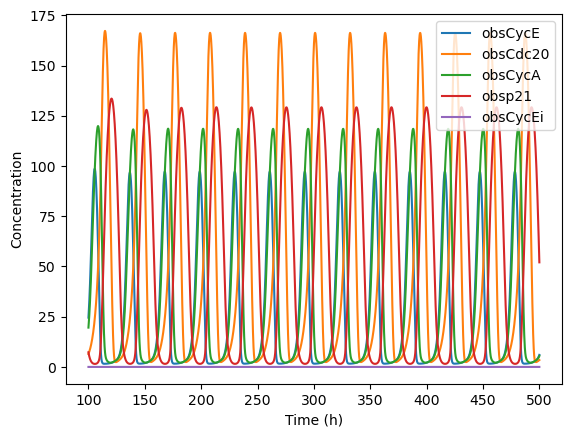

In [7]:

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(1000,5000), legend=True)


### Simulate model with stochastic simulator

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False, seed=33)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

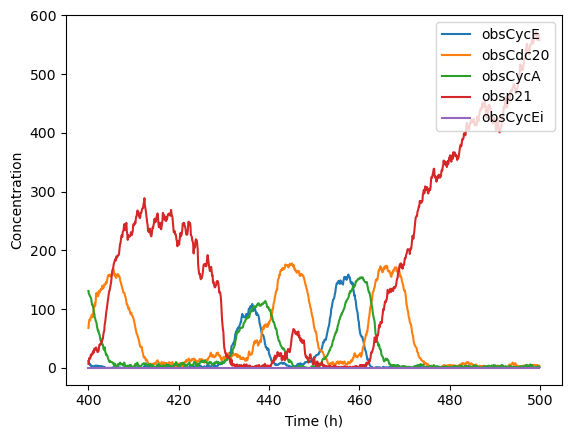

In [9]:
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(4000,5000), legend=True)

In [10]:
ecm_conditions = pd.read_csv('ECM_conditions.csv', index_col=[0])
ecm_conditions

,stiffness,drug,species,value
condition,,,,
stiff_DMSO,stiff,DMSO,AKT,1.0
stiff_DMSO,stiff,DMSO,ERK,1.0
stiff_DMSO,stiff,DMSO,FAK,1.0
int_DMSO,intermediate,DMSO,AKT,1.0
int_DMSO,intermediate,DMSO,ERK,1.0
int_DMSO,intermediate,DMSO,FAK,0.6
soft_DMSO,soft,DMSO,AKT,0.6
soft_DMSO,soft,DMSO,ERK,1.0
soft_DMSO,soft,DMSO,FAK,0.4


In [11]:
conditions = ecm_conditions.index.unique().tolist()
conditions


['stiff_DMSO', 'int_DMSO', 'soft_DMSO', 'stiff_erl', 'int_erl', 'soft_erl']

### Set CDK4/6i value; initially there is no inhibitor

In [12]:
model.parameters['CycDi_0'].value = 0

### ODE simulations

In [13]:
for condition in ecm_conditions.index.unique().tolist():
    input_vals = pd.Series(ecm_conditions.loc[condition]['value'].to_list())
    input_vals.index = ecm_conditions.loc[condition]['species'].to_list()
    model.parameters['ERK'].value = input_vals['ERK']
    model.parameters['FAK'].value = input_vals['FAK']
    model.parameters['AKT'].value = input_vals['AKT']

    print(f"Running ODE simulation for {condition}...")
   
    simres = ScipyOdeSimulator(model, t, verbose=False, compiler='cython').run(); #deterministic simulation
    yout = simres.observables

    cycdi = str(round(model.parameters['CycDi_0'].value % 1,2)).split('.')[1]
    if SET_JPARAM:
        filename = Path(SAVE_DIR, f'ODE_sim_{condition}_psoparam_cycdi_0_{cycdi}.csv')
    else:
        filename = Path(SAVE_DIR, f'ODE_sim_{condition}_param_cycdi_0_{cycdi}.csv')
    if OVERWRITE or not os.path.exists(filename):
        print(f"Saving to {filename}...")
        np.savetxt(filename, yout, delimiter=',')
    else:
        print(f"File {filename} already exists. Skipping...")

Running ODE simulation for stiff_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_0.csv...
Running ODE simulation for int_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_int_DMSO_param_cycdi_0_0.csv...
Running ODE simulation for soft_DMSO...
Saving to /Users/darren/ECM_mod_output/ODE_sim_soft_DMSO_param_cycdi_0_0.csv...
Running ODE simulation for stiff_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_0.csv...
Running ODE simulation for int_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_int_erl_param_cycdi_0_0.csv...
Running ODE simulation for soft_erl...
Saving to /Users/darren/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv...


### Stochastic simulations

In [14]:
for condition in ecm_conditions.index.unique().tolist():
    input_vals = pd.Series(ecm_conditions.loc[condition]['value'].to_list())
    input_vals.index = ecm_conditions.loc[condition]['species'].to_list()
    model.parameters['ERK'].value = input_vals['ERK']
    model.parameters['FAK'].value = input_vals['FAK']
    model.parameters['AKT'].value = input_vals['AKT']

    print(f"Running stochastic simulation for {condition}...")

    sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
    simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
    yout = simres.observables;

    cycdi = str(round(model.parameters['CycDi_0'].value % 1,2)).split('.')[1]
    if SET_JPARAM:
        filename = Path(SAVE_DIR, f'stoch_sim_{condition}_psoparam_cycdi_0_{cycdi}.csv')
    else:
        filename = Path(SAVE_DIR, f'stoch_sim_{condition}_param_cycdi_0_{cycdi}.csv')
    if OVERWRITE or not os.path.exists(filename):
        print(f"Saving to {filename}...")
        np.savetxt(filename, yout, delimiter=',')
    else:
        print(f"File {filename} already exists. Skipping...")

Running stochastic simulation for stiff_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv...
Running stochastic simulation for int_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv...
Running stochastic simulation for soft_DMSO...
Saving to /Users/darren/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv...
Running stochastic simulation for stiff_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv...
Running stochastic simulation for int_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv...
Running stochastic simulation for soft_erl...
Saving to /Users/darren/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv...
